# Hệ thống Phân tích Cảm xúc TikTok Song ngữ (Tiếng Việt & Tiếng Anh)

- **Nguồn đầu vào (2 chế độ):** **1. Link TikTok** (Chuẩn bị dữ liệu: tự tải video/ảnh, crawl comment + reply và phân tích nội dung video lưu vào `data/<post_id>/`) hoặc **2. Thư mục đã chuẩn bị sẵn** (`data/<post_id>/` chứa `raw_comments.csv`, video/ảnh & `media_context.json`).
- **Chuẩn bị dữ liệu & Giai đoạn 1 (`gemma4-e2b-opt` + Whisper):** Trích khung hình có mốc thời gian (`768px`, tự động 2-pass cho slideshow dài) + lời thoại Whisper + caption thành JSON Evidence-First (11 trường) và lưu vào `data/<post_id>/media_context.json` để tái sử dụng cho Giai đoạn 2–3 mà không cần chạy lại Gemma 4.
- **Giai đoạn 2 — Tiền xử lý & Lọc nhiễu có ngữ cảnh (`src/preprocessing/text_cleaner.py`):** Nhận diện ngôn ngữ (`vi` / `en`), bảo vệ thực thể video không bị lọc nhầm, lọc nhiễu, tách từ `underthesea` và tính độ liên quan chủ đề (`is_on_topic`, `context_relevance`).
- **Giai đoạn 3 — Lõi ML & Deep Learning (`src/models/classical_ml.py` + `sentiment_engine.py`):** Giữ chuẩn NLP đánh giá cảm xúc từng bình luận (`TF-IDF NB/LR/SVM`, `Lexicon`, `ViSoBERT`, `PhoBERT`, `Twitter-RoBERTa`, `Emotion 7 cung bậc`) kết hợp tầng Context Alignment (`context_alignment` xuất tại `detailed_model_outputs.csv`).
- **Giai đoạn 4 — AI Đầu ra (`src/models/gemma_auditor.py`, mặc định TẮT):** Khi bật `RUN_AI_AUDIT = True`, `gemma4-e2b-opt` thẩm định các ca mỉa mai sâu & kết quả Giai đoạn 3 dựa trên `media_context.json`; xuất 6 tệp gọn ra `outputs/<run_name>/` (`final_results.csv` sắp theo likes, `detailed_model_outputs.csv`, `filtered_noise.csv`, `model_comparison.csv`, `report.json`, `dashboard.png`).

> Lưu ý: Chỉ cần khởi động container Ollama `gemma4-e2b` khi trích xuất mới `media_context.json` ở Giai đoạn 1 hoặc khi bật Giai đoạn 4 (`RUN_AI_AUDIT = True`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.pipeline import SentimentPipeline
from src.visualization import plot_sentiment_dashboard
# Nhật anh project
# === TÙY CHỌN GÁN CỨNG (để None nếu muốn notebook hỏi tương tác khi chạy) ===
INPUT_MODE = None            # None (hỏi trực tiếp) | "url" | "folder"
TIKTOK_URL = ""
INPUT_DIR = None             # Đường dẫn thư mục đã chuẩn bị sẵn (vd: "data/7711719899852295445") cho chế độ "folder"
RUN_MEDIA_ANALYSIS = True    # True = dùng/trích xuất media_context.json; False = bỏ qua ngữ cảnh video
FORCE_REANALYZE_MEDIA = False # True = ép Gemma 4 + Whisper phân tích lại dù đã có media_context.json
PREPARE_ONLY = False         # True = chỉ Chuẩn bị dữ liệu vào data/<post_id>/ rồi dừng
RUN_AI_AUDIT = False         # Mặc định TẮT Giai đoạn 4 (đặt True để bật Gemma 4 thẩm định ca mỉa mai sâu, hoặc None để hỏi)

# === CHỌN NGUỒN ĐẦU VÀO ===
if INPUT_MODE is None:
    print("Chọn nguồn dữ liệu đầu vào:")
    print("  1. Link TikTok (Chuẩn bị dữ liệu: tải media, crawl comment + reply & lưu vào data/<post_id>/)")
    print("  2. Thư mục đã chuẩn bị sẵn (vd: data/<post_id>)")
    _choice = input("Nhập lựa chọn [1/2, mặc định 1]: ").strip() or "1"
    INPUT_MODE = {"1": "url", "2": "folder"}.get(_choice, "url")

if INPUT_MODE == "url":
    if not TIKTOK_URL:
        TIKTOK_URL = input("Nhập link video/ảnh TikTok: ").strip().strip('"\'')
elif INPUT_MODE == "folder":
    if not INPUT_DIR:
        INPUT_DIR = input("Nhập đường dẫn thư mục (vd: data/7711719899852295445): ").strip().strip('"\'')
else:
    raise ValueError(f"INPUT_MODE không hợp lệ: {INPUT_MODE} (chỉ hỗ trợ 'url' hoặc 'folder').")

# === TÙY CHỌN GIAI ĐOẠN 4 (THẨM ĐỊNH BẰNG AI — MẶC ĐỊNH TẮT) ===
if RUN_AI_AUDIT is None:
    _ans = input("Có chạy Giai đoạn 4 (dùng AI Gemma 4 thẩm định ca mỉa mai sâu & kết quả Giai đoạn 3) không? [y/N, mặc định N]: ").strip().lower()
    RUN_AI_AUDIT = True if _ans in {"y", "yes", "c", "co", "có", "1"} else False

# === CẤU HÌNH HỆ THỐNG ===
ENABLE_AUDIO = True
AUDIT_LIMIT = None             # None = chấm 100% bình luận hợp lệ khi bật AI Audit
MAX_COMMENTS = 2000            # Số lượng bình luận tối đa cần thu thập (cả comment + reply)
INCLUDE_REPLIES = True         # Thu thập cả bình luận trả lời (reply)
MAX_REPLIES_PER_COMMENT = None # None = lấy toàn bộ reply tới khi chạm MAX_COMMENTS
DEDUPLICATE_STATS = False      # True nếu muốn loại bỏ bình luận copy-paste khỏi tỷ lệ %
DATA_DIR = Path("data")        # Nơi lưu toàn bộ dữ liệu chuẩn bị đầu vào (video, comments, media_context.json)
OUTPUT_DIR = Path("outputs")   # Nơi xuất kết quả cuối cùng sau xử lý

print(f"-> Chế độ đầu vào: {INPUT_MODE} | Media Context: {RUN_MEDIA_ANALYSIS} | Prepare Only: {PREPARE_ONLY} | Giai đoạn 4 (AI Audit): {RUN_AI_AUDIT}")

Chọn nguồn dữ liệu đầu vào:
  1. Link TikTok (Chuẩn bị dữ liệu: tải media, crawl comment + reply & lưu vào data/<post_id>/)
  2. Thư mục đã chuẩn bị sẵn (vd: data/<post_id>)
-> Chế độ đầu vào: url | Media Context: True | Prepare Only: False | Giai đoạn 4 (AI Audit): False


In [2]:
# === CHẠY TOÀN BỘ PIPELINE ===
if INPUT_MODE == "url" and not TIKTOK_URL:
    raise ValueError("Vui lòng nhập link TikTok vào biến TIKTOK_URL.")
if INPUT_MODE == "folder" and not INPUT_DIR:
    raise ValueError("Vui lòng nhập đường dẫn thư mục vào biến INPUT_DIR.")

pipeline = SentimentPipeline()
report = pipeline.run(
    tiktok_url=TIKTOK_URL if INPUT_MODE == "url" else None,
    input_dir=INPUT_DIR if INPUT_MODE == "folder" else None,
    enable_audio=ENABLE_AUDIO,
    run_media_analysis=RUN_MEDIA_ANALYSIS,
    force_reanalyze_media=FORCE_REANALYZE_MEDIA,
    prepare_only=PREPARE_ONLY,
    run_ai_audit=RUN_AI_AUDIT,
    audit_limit=AUDIT_LIMIT,
    max_comments=MAX_COMMENTS,
    include_replies=INCLUDE_REPLIES,
    max_replies_per_comment=MAX_REPLIES_PER_COMMENT,
    deduplicate_stats=DEDUPLICATE_STATS,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
)

run_name = report["run_name"]
if report.get("prepare_only"):
    print(f"-> Đã chuẩn bị xong dữ liệu tại: {report.get('data_dir')}")
    print(f"-> Tệp media_context.json: {report.get('media_context_path')}")
else:
    print(f"-> Kết quả xử lý xuất tại: {OUTPUT_DIR / run_name}")

if report.get("media_analysis"):
    print("\n=== NỘI DUNG VIDEO / ẢNH (media_context.json) ===")
    print(json.dumps(report["media_analysis"], ensure_ascii=False, indent=2))

[Chuẩn bị dữ liệu] Đang tải video/ảnh & metadata vào data\7710909877958282514...
[Chuẩn bị dữ liệu] Đang thu thập bình luận vào data\7710909877958282514\raw_comments.csv...
Đang mở trình duyệt tới: https://www.tiktok.com/@memory13988/video/7710909877958282514?lang=vi-VN

[Tạm dừng] Trên cửa sổ trình duyệt vừa mở:
  1. Đóng popup đăng nhập (hoặc đăng nhập nếu TikTok yêu cầu).
  2. Mở phần bình luận (nếu chưa hiện) hoặc hoàn tất xác minh (nếu có).
  Lần cuộn 1/40: thu được 41 bình luận (36 chính, 5 reply)
  Lần cuộn 2/40: thu được 57 bình luận (52 chính, 5 reply)
  Lần cuộn 3/40: thu được 72 bình luận (67 chính, 5 reply)
  Lần cuộn 4/40: thu được 72 bình luận (67 chính, 5 reply)
  Lần cuộn 5/40: thu được 92 bình luận (87 chính, 5 reply)
  Lần cuộn 6/40: thu được 104 bình luận (99 chính, 5 reply)
  Lần cuộn 7/40: thu được 104 bình luận (99 chính, 5 reply)
  Lần cuộn 8/40: thu được 104 bình luận (99 chính, 5 reply)
  Lần cuộn 9/40: thu được 104 bình luận (99 chính, 5 reply)
  Lần cuộn 10/4

c:\Users\Admin\miniconda3\envs\hand_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  -> Hợp lệ: 83 | Đã lọc nhiễu: 21
[Giai đoạn 3] Đang chạy ML cổ điển, Lexicon, Deep Learning (VI/EN) & Context Alignment...
[Classical ML - VI] Đang nạp dữ liệu để huấn luyện NB, LR, SVM...
[Classical ML - EN] Đang nạp dữ liệu để huấn luyện NB, LR, SVM...


Model phobert-emotion: 100%|██████████| 3/3 [00:03<00:00,  1.26s/batch]
Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Model emotion-english-distilroberta-base: 100%|██████████| 1/1 [00:00<00:00,  3.68batch/s]


[Giai đoạn 4] Đã bỏ qua thẩm định AI theo tùy chọn người dùng (run_ai_audit=False).
-> Kết quả xử lý xuất tại: outputs\7710909877958282514

=== NỘI DUNG VIDEO / ẢNH (media_context.json) ===
{
  "media_type": "video",
  "source_paths": [
    "data\\7710909877958282514\\video.mp4"
  ],
  "num_frames_used": 8,
  "has_audio": true,
  "caption": "TikTok video #7710909877958282514",
  "transcript": "[00:00-00:02] ha ha ha ha ha ha",
  "chu_de_chinh": "So sánh về yếu tố kinh tế (tiền tệ) và tinh thần dân tộc trong chiến thắng lịch sử giữa Việt Nam và Trung Quốc.",
  "muc_dich_chinh": "Làm rõ sự khác biệt về yếu tố quyết định chiến thắng giữa Việt Nam và Trung Quốc thông qua việc so sánh đơn vị tiền tệ và lòng dân.",
  "quan_diem_noi_dung": "Phân tích và bình luận về vai trò của tiền tệ (VND vs NDT) và tinh thần dân tộc trong các sự kiện lịch sử, đặc biệt là chiến thắng của Việt Nam.",
  "doi_tuong_chinh": [
    "Việt Nam",
    "Trung Quốc",
    "Tiền tệ (VND và NDT)",
    "Tinh thần dân tộc"


In [3]:
# === XEM KẾT QUẢ TÁCH BIỆT COMMENT SẠCH, CHI TIẾT MÔ HÌNH & COMMENT NHIỄU ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (chưa chạy Giai đoạn 2 & 3). Hãy đặt PREPARE_ONLY=False để phân tích cảm xúc.")
else:
    print("=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===")
    print(json.dumps(report["noise_filter_summary"], ensure_ascii=False, indent=2))
    if report.get("sentiment_summary"):
        print("Phân bố ngôn ngữ hợp lệ:", report["sentiment_summary"]["language_counts"])
        if report["sentiment_summary"].get("on_topic_summary"):
            print("Thống kê nhóm bám sát nội dung video:", json.dumps(report["sentiment_summary"]["on_topic_summary"], ensure_ascii=False, indent=2))

    exported = report.get("exported_files", {})
    if "final_results_csv" in exported:
        df_clean = pd.read_csv(exported["final_results_csv"], encoding="utf-8-sig")
        print(f"\nBảng kết quả dễ đọc (final_results.csv — {len(df_clean.columns)} cột, đã sắp theo lượt thích giảm dần): {len(df_clean)} dòng")
        display(df_clean.head(20))

    if "detailed_model_outputs_csv" in exported:
        df_detail = pd.read_csv(exported["detailed_model_outputs_csv"], encoding="utf-8-sig")
        print(f"\nBảng chi tiết mô hình, ngữ cảnh video & xác suất (detailed_model_outputs.csv — {len(df_detail.columns)} cột): {len(df_detail)} dòng")
        display(df_detail.head(10))

    if "filtered_noise_csv" in exported:
        df_noise = pd.read_csv(exported["filtered_noise_csv"], encoding="utf-8-sig")
        print(f"\nSố comment bị lọc nhiễu (filtered_noise.csv): {len(df_noise)}")
        display(df_noise.head(20))

=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===
{
  "total_raw_comments": 104,
  "valid_comments": 83,
  "filtered_noise_count": 21,
  "duplicate_valid_count": 4,
  "filter_reasons": {
    "FILTERED_URL_OR_SYMBOL": 21
  }
}
Phân bố ngôn ngữ hợp lệ: {'vi': 80, 'en': 3}
Thống kê nhóm bám sát nội dung video: {
  "on_topic_count": 12,
  "on_topic_pct": 14.46,
  "off_topic_count": 71,
  "avg_context_relevance": 0.1051,
  "on_topic_polarity_counts": {
    "POS": 2,
    "NEG": 5,
    "NEU": 5
  },
  "on_topic_polarity_percentages": {
    "POS": 16.67,
    "NEG": 41.67,
    "NEU": 41.67
  },
  "alignment_counts": {
    "Bức xúc / Tiêu cực về chủ đề video (cần xét đồng tình hay công kích)": 5,
    "Ít liên quan / Bình luận ngoài lề": 65,
    "Ủng hộ / Tích cực với video": 4,
    "Thảo luận trung lập về chủ đề video (cần kiểm tra ẩn ý)": 4,
    "Nghi ngờ mỉa mai / Cần AI kiểm tra ngữ cảnh": 3,
    "Ủng hộ / Tích cực với nội dung video": 2
  }
}

Bảng kết quả dễ đọc (final_results.csv — 12 cột, đã sắp theo

,stt\n(số thứ tự),original_text\n(nội dung bình luận),polarity_vi\n(sắc thái),polarity_confidence\n(độ tự tin sắc thái %),emotion_vi\n(cảm xúc),emotion_confidence\n(độ tự tin cảm xúc %),likes\n(lượt thích),comment_type\n(loại bình luận),username\n(tài khoản),language\n(ngôn ngữ),created_at\n(thời gian đăng),reply_count\n(số phản hồi)
0,1,thế cũng nghĩ ra dc🤣,Tích cực,55.8%,Vui vẻ / Hài lòng,98.0%,25,Bình luận chính,din.nguyn761,Tiếng Việt,2026-11-22 16:51:03,1
1,2,cũng đúng nha,Tích cực,71.5%,Vui vẻ / Hài lòng,98.3%,9,Bình luận chính,quan28hb,Tiếng Việt,2026-11-22 16:07:13,0
2,3,1. Ý nghĩa của tên gọi Nhân dân tệ\nTên tiếng ...,Tiêu cực,73.7%,Chán ghét / Khó chịu,53.2%,7,Bình luận chính,cachepmaymann,Tiếng Việt,2026-11-22 18:11:36,15
3,4,"Này giải nghĩa được nè 9,5 điểm",Tích cực,78.5%,Vui vẻ / Hài lòng,94.8%,3,Bình luận chính,nguyn.trn.hng,Tiếng Việt,2026-11-24 07:22:45,0
4,5,ông nào nghi ra này tui nể that,Trung tính,47.7%,Vui vẻ / Hài lòng,78.0%,3,Bình luận chính,luonghoavinhlong,Tiếng Việt,2026-11-22 20:43:00,0
5,6,1. Ý nghĩa của tên gọi Việt Nam đồng\nTên gọi ...,Trung tính,40.4%,Trung tính / Khác,77.2%,3,Trả lời,cachepmaymann,Tiếng Việt,2026-11-22 18:12:07,0
6,7,"Đúng, đúng nè😁😁😁😁😁😁",Tích cực,82.2%,Vui vẻ / Hài lòng,97.8%,3,Bình luận chính,tiu.bao.bao770,Tiếng Việt,2026-11-22 17:10:57,0
7,8,Hay 🤝👍❤️. Khó thế mà Bạn cũng nghĩ ra được 😁😁😁👍❤️,Tích cực,84.0%,Vui vẻ / Hài lòng,98.9%,2,Bình luận chính,user2343737735695,Tiếng Việt,2026-11-23 17:43:20,0
8,9,ồ đúng nhỉ,Tích cực,66.0%,Ngạc nhiên,62.8%,2,Bình luận chính,nghiemhanh568,Tiếng Việt,2026-11-22 18:08:19,0
9,10,vậy cũng nghĩ ra hay,Trung tính,44.6%,Vui vẻ / Hài lòng,99.2%,2,Bình luận chính,thuquynh9982,Tiếng Việt,2026-11-22 18:23:58,0



Bảng chi tiết mô hình, ngữ cảnh video & xác suất (detailed_model_outputs.csv — 29 cột): 83 dòng


,stt\n(số thứ tự),comment_id\n(mã bình luận),parent_comment_id\n(mã bình luận gốc),username\n(tài khoản),nickname\n(tên hiển thị),likes\n(lượt thích),original_text\n(nội dung gốc),cleaned_text\n(nội dung đã làm sạch),segmented_text\n(văn bản đã tách từ),is_duplicate\n(bình luận trùng lặp),...,score_NEG\n(xác suất tiêu cực),score_NEU\n(xác suất trung tính),emotion_label\n(nhãn cảm xúc chuẩn),pred_nb\n(dự đoán naive bayes),pred_lr\n(dự đoán logistic regression),pred_svm\n(dự đoán linear svm),pred_lexicon\n(dự đoán từ điển luật),pred_visobert\n(dự đoán visobert),pred_dl_primary\n(dự đoán học sâu chính),emotion_ml_label\n(cảm xúc ml cổ điển)
0,1,7710930157058540308,NaN,din.nguyn761,bắcninh9899,25,thế cũng nghĩ ra dc🤣,thế cũng nghĩ ra được🤣,thế cũng nghĩ ra được 🤣,False,...,0.0552,0.3867,Enjoyment,NEG,POS,POS,NEU,POS,NEU,Surprise
1,2,7710919775119754005,NaN,quan28hb,Quận 28hb,9,cũng đúng nha,cũng đúng nha,cũng đúng nha,False,...,0.0319,0.2531,Enjoyment,POS,POS,POS,NEU,POS,POS,Enjoyment
2,3,7710951833917309704,NaN,cachepmaymann,Cá chép may mắn,7,1. Ý nghĩa của tên gọi Nhân dân tệ\nTên tiếng ...,1. Ý nghĩa của tên gọi Nhân dân tệ Tên tiếng T...,1 . Ý_nghĩa của tên gọi Nhân_dân_tệ Tên tiếng ...,False,...,0.7370,0.1287,Disgust,NEG,NEG,NEG,NEU,NEG,NEG,Disgust
3,4,7711526753344848647,NaN,nguyn.trn.hng,Nguyên Trần Hương,3,"Này giải nghĩa được nè 9,5 điểm","Này giải nghĩa được nè 9,5 điểm","Này giải_nghĩa được nè 9,5 điểm",False,...,0.0372,0.1774,Enjoyment,POS,POS,POS,NEU,POS,POS,Enjoyment
4,5,7710990873253397268,NaN,luonghoavinhlong,Fương Fương (Bánh tét Bến Tre),3,ông nào nghi ra này tui nể that,ông nào nghi ra này tui nể that,ông nào nghi ra này tui nể that,False,...,0.2648,0.4769,Enjoyment,NEU,NEU,NEG,NEU,NEG,NEU,Surprise
5,6,7710951989547139858,7.710952e+18,cachepmaymann,Cá chép may mắn,3,1. Ý nghĩa của tên gọi Việt Nam đồng\nTên gọi ...,1. Ý nghĩa của tên gọi Việt Nam đồng Tên gọi g...,1 . Ý_nghĩa của tên gọi Việt_Nam đồng_Tên gọi ...,False,...,0.2535,0.4042,Other,NEG,NEG,NEG,NEG,POS,NEU,Disgust
6,7,7710936188191179528,NaN,tiu.bao.bao770,Tiểu bao bao,3,"Đúng, đúng nè😁😁😁😁😁😁","Đúng, đúng nè😁😁","Đúng , đúng nè 😁 😁",False,...,0.0308,0.1474,Enjoyment,POS,POS,POS,NEU,POS,POS,Enjoyment
7,8,7711314771849642760,NaN,user2343737735695,Hiền Vũ,2,Hay 🤝👍❤️. Khó thế mà Bạn cũng nghĩ ra được 😁😁😁👍❤️,Hay 🤝👍❤️. Khó thế mà Bạn cũng nghĩ ra được 😁😁😁👍❤️,Hay 🤝_👍 ❤_️ . Khó thế mà Bạn cũng nghĩ ra được...,False,...,0.0535,0.1064,Enjoyment,NEG,POS,POS,POS,POS,POS,Enjoyment
8,9,7710950995757482759,NaN,nghiemhanh568,nghiêm hạnh,2,ồ đúng nhỉ,ồ đúng nhỉ,ồ đúng nhỉ,False,...,0.0393,0.3006,Surprise,NEU,NEU,POS,NEU,POS,POS,Surprise
9,10,7710955010667070216,NaN,thuquynh9982,Kim Loan,2,vậy cũng nghĩ ra hay,vậy cũng nghĩ ra hay,vậy cũng nghĩ ra hay,False,...,0.2047,0.4464,Enjoyment,NEU,NEU,POS,POS,NEG,NEU,Enjoyment



Số comment bị lọc nhiễu (filtered_noise.csv): 21


,stt\n(số thứ tự),original_text\n(nội dung gốc),filter_reason_vi\n(lý do lọc),filter_reason\n(mã lý do lọc),language\n(ngôn ngữ),likes\n(lượt thích),username\n(tài khoản),nickname\n(tên hiển thị),comment_id\n(mã bình luận)
0,1,😜😜😜😜,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,user6777830622751,user6777830622751,7710964407456006919
1,2,😂😂😂,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,phuongssushi,Phuong🍣,7711939148148867860
2,3,😁😁😁,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,lehoangkyanh,Lê Hoàng Kỳ Anh,7711901489271407381
3,4,😂😂😂,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,tomcoca90,tomcoca.,7711426100496679686
4,5,😂😂,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,phuongkim4,Phuong Kim,7710947237791400724
5,6,😄😄😄👍,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,huynhhuong736,HuỳnhHương玉香🇻🇳🇹🇼,7710946359353262866
6,7,😂,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,hanguyen_van,hanguyen_van,7710944101503632135
7,8,🤣🤣🤣🤣🤣🤣🤣🥰🥰,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,user4917229191,Thúy Nguyễn,7710930851936338740
8,9,😁😁😁,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,nhungyencangio,NHUNG YẾN CẦN GIỜ,7711565324629738241
9,10,😅😅😅,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,1,minh.t1237,Minh Tú,7711449017879806726


In [4]:
# === SO SÁNH CÁC MÔ HÌNH ML CỔ ĐIỂN VS DEEP LEARNING VS HYBRID ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (bỏ qua so sánh mô hình).")
else:
    comp = report.get("model_comparison", {})
    if comp.get("polarity_models"):
        print("=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===")
        df_pol_comp = pd.DataFrame(comp["polarity_models"])
        display(df_pol_comp.dropna(axis=1, how="all"))

    if comp.get("emotion_models"):
        print("\n=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===")
        df_emo_comp = pd.DataFrame(comp["emotion_models"])
        display(df_emo_comp.dropna(axis=1, how="all"))

    if report.get("ai_audit_verdict"):
        print("\n=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===")
        print(json.dumps(report["ai_audit_verdict"], ensure_ascii=False, indent=2))
    else:
        print("\n[Giai đoạn 4] Đã bỏ qua thẩm định AI theo cấu hình mặc định (RUN_AI_AUDIT=False).")

    if report.get("keywords_tfidf"):
        print("\n=== TỪ KHÓA NỔI BẬT (TF-IDF) ===")
        print(json.dumps(report["keywords_tfidf"], ensure_ascii=False, indent=2))

=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===


,model,family,total_comments,pos_count,neu_count,neg_count,pos_pct,neu_pct,neg_pct,inference_time_sec
0,TF-IDF + Naive Bayes,Classical ML,83,19,27,37,22.89,32.53,44.58,0.014
1,TF-IDF + Logistic Regression,Classical ML,83,38,30,15,45.78,36.14,18.07,0.014
2,TF-IDF + Linear SVM,Classical ML,83,45,15,23,54.22,18.07,27.71,0.014
3,Bilingual Lexicon + Rules,Rule-based NLP,83,25,52,6,30.12,62.65,7.23,0.001
4,"ViSoBERT (5CD-AI, VI)",Deep Learning,80,60,2,18,75.00,2.50,22.50,5.234
5,PhoBERT (VI) / Twitter-RoBERTa (EN),Deep Learning,83,39,26,18,46.99,31.33,21.69,8.647
6,Hybrid Ensemble (Hệ thống chính),Hybrid ML + DL,83,42,23,18,50.60,27.71,21.69,NaN



=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===


,model,family,inference_time_sec
0,TF-IDF + Logistic Regression (Emotion),Classical ML,0.009
1,PhoBERT Emotion (VI) / DistilRoBERTa (EN),Deep Learning,7.330



[Giai đoạn 4] Đã bỏ qua thẩm định AI theo cấu hình mặc định (RUN_AI_AUDIT=False).

=== TỪ KHÓA NỔI BẬT (TF-IDF) ===
{
  "overall": [
    {
      "keyword": "hay",
      "tfidf_score": 0.1083
    },
    {
      "keyword": "nghĩ",
      "tfidf_score": 0.0845
    },
    {
      "keyword": "đúng",
      "tfidf_score": 0.0758
    },
    {
      "keyword": "khó nghĩ",
      "tfidf_score": 0.0374
    },
    {
      "keyword": "khó",
      "tfidf_score": 0.0374
    },
    {
      "keyword": "chuẩn",
      "tfidf_score": 0.0326
    },
    {
      "keyword": "giỏi",
      "tfidf_score": 0.0239
    },
    {
      "keyword": "có",
      "tfidf_score": 0.0218
    },
    {
      "keyword": "vn",
      "tfidf_score": 0.0203
    },
    {
      "keyword": "đồng lòng",
      "tfidf_score": 0.0188
    }
  ],
  "positive": [
    {
      "keyword": "hay",
      "tfidf_score": 0.2028
    },
    {
      "keyword": "đúng",
      "tfidf_score": 0.1149
    },
    {
      "keyword": "nghĩ",
      "tfidf_score":

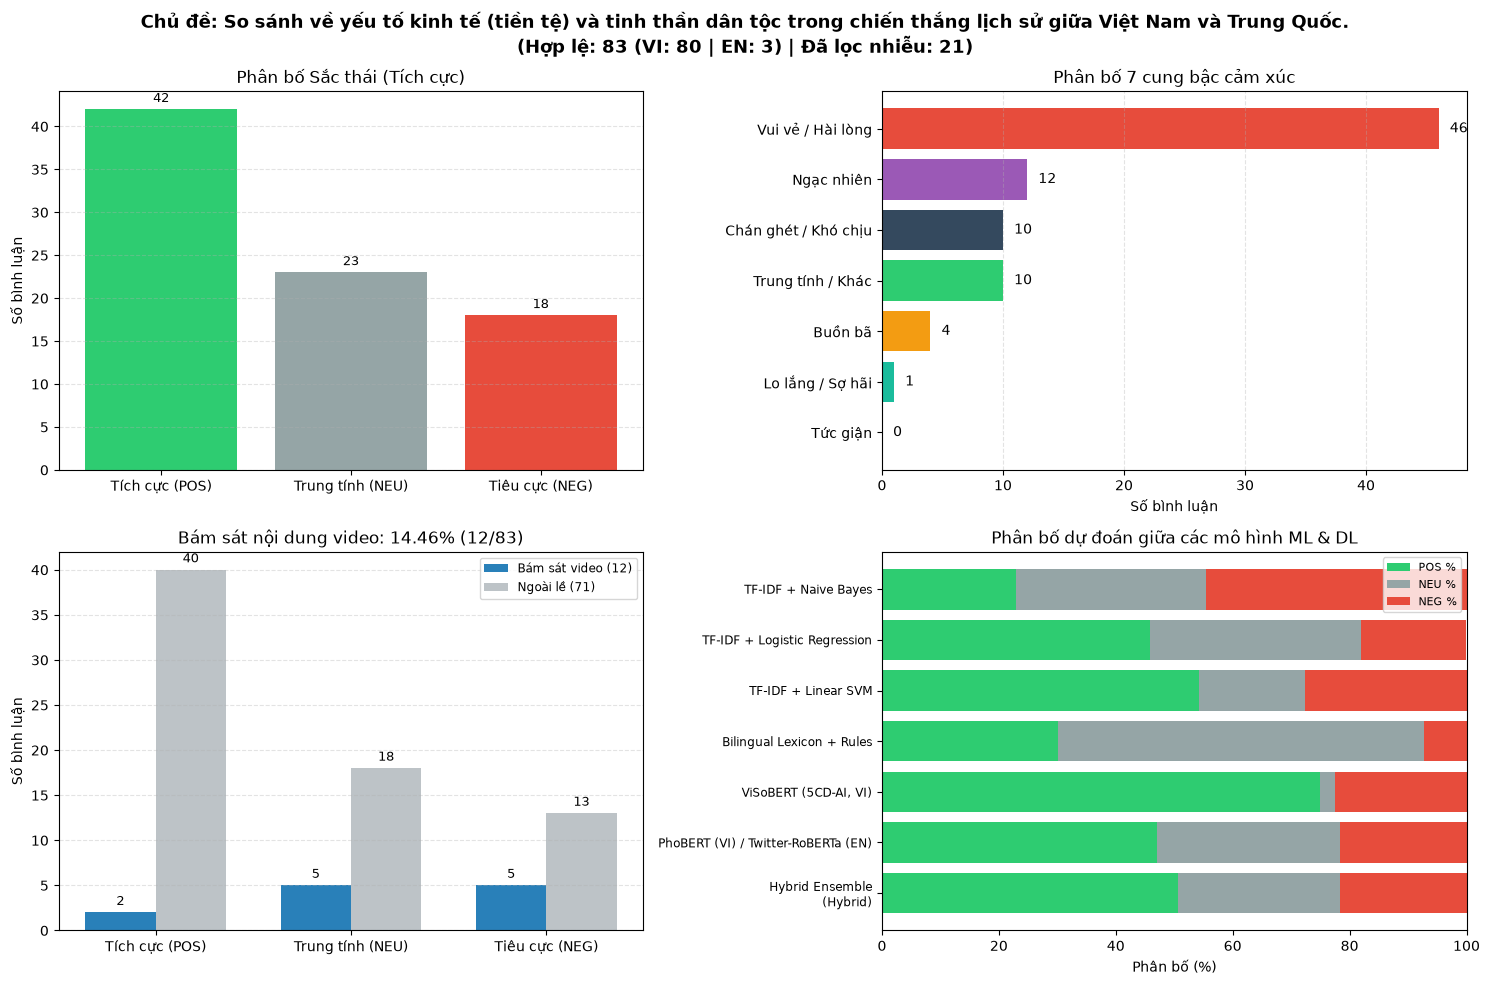

In [5]:
# === DASHBOARD TRỰC QUAN HÓA ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (không vẽ dashboard).")
else:
    summary = report.get("sentiment_summary") or {}
    if summary.get("total_valid_comments", 0) > 0:
        exported = report.get("exported_files", {})
        chart_path = exported.get("dashboard_png") or (OUTPUT_DIR / report["run_name"] / "dashboard.png")
        fig = plot_sentiment_dashboard(report, save_path=chart_path)
        plt.show()
    else:
        print("Không có bình luận hợp lệ để vẽ dashboard.")